# Assignment 2

## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

In [9]:
import json
import os


def extract_texts_from_file(file_path):
    """Extract ALL data from the json file and format each record as a text string.

    Args:
        file_path (str): Relative location of the json file in the project.

    Returns:
        list: The list of formatted texts as strings.
    """
    if not os.path.exists(file_path):
        alt_path = os.path.basename(file_path)
        if os.path.exists(alt_path):
            file_path = alt_path

    try:
        with open(file_path, "r", encoding="utf-8") as f:
            data = json.load(f)
    except Exception as e:
        print(f"Помилка відкриття файлу {file_path}: {e}")
        return []

    texts = []

    # 1. Якщо це словник із ключем "texts" (як у вашому data.json)
    if isinstance(data, dict) and "texts" in data:
        texts = [str(item) for item in data["texts"] if item]

    # 2. Якщо це словник з іншими ключами
    elif isinstance(data, dict):
        for val in data.values():
            if isinstance(val, list):
                texts.extend([str(item) for item in val if item])
            elif isinstance(val, str):
                texts.append(val)

    # 3. Якщо у JSON одразу збережено масив ["text1", "text2", ...]
    elif isinstance(data, list):
        texts = [str(item) for item in data if item]

    return texts


texts = extract_texts_from_file("resources/data.json")
print(texts)

['Oppenheimer, directed by Christopher Nolan, delves into the life of J. Robert Oppenheimer, the theoretical physicist who led the development of the atomic bomb. The film explores his moral and emotional struggles.', "Oppenheimer captures the life of the 'father of the atomic bomb' and his internal conflict after the success of the Manhattan Project. The film's complex narrative reflects on the cost of scientific achievement.", 'In Oppenheimer, Cillian Murphy delivers a riveting performance as the conflicted physicist who grapples with the consequences of his groundbreaking work on the atomic bomb, under the weight of global politics and ethics.', 'Oppenheimer is a cinematic exploration of ambition, guilt, and responsibility. Through stunning visuals and a thought-provoking story, Nolan brings the life of the brilliant but haunted physicist to the big screen.', 'Ducks are versatile waterfowl, known for their adaptability in freshwater and coastal habitats. With webbed feet and waterpr

## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

In [10]:
import re
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from spellchecker import SpellChecker

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

ABBREVIATIONS = {
    "don't": "do not",
    "can't": "cannot",
    "won't": "will not",
    "i'm": "i am",
    "it's": "it is",
    "you're": "you are",
    "they're": "they are",
    "e.g.": "for example",
    "i.e.": "that is",
    "etc.": "et cetera",
}


def expand_abbreviations(text):
  for abbr, full in ABBREVIATIONS.items():
    text = re.sub(
        r'(?<!\w)' + re.escape(abbr) + r'(?!\w)', full, text, flags=re.IGNORECASE
    )
  return text


def process_texts(texts):
  """Process the texts through lowercasing, handling abbreviations, removing

  punctuation/numbers, spelling correction, and lemmatization.

  Args:
      texts (list): list of str texts to be processed.

  Returns:
      list: The list of texts as strings processed by script.
  """
  if not texts:
    return []

  lemmatizer = WordNetLemmatizer()
  spell = SpellChecker()
  processed_list = []

  for text in texts:
    if not isinstance(text, str):
      continue
        
    clean_text = text.lower()
    clean_text = expand_abbreviations(clean_text)
    clean_text = re.sub(r'[^a-zA-Z\s]', ' ', clean_text)

    tokens = word_tokenize(clean_text)

    processed_tokens = []
    for word in tokens:
      corrected_word = spell.correction(word)
      word = corrected_word if corrected_word else word

      lemma = lemmatizer.lemmatize(word)
      processed_tokens.append(lemma)

    processed_list.append(' '.join(processed_tokens))

  return processed_list

texts_processed = process_texts(texts)
print(texts_processed)

['oppenheimer directed by christopher nolan delf into the life of j robert oppenheimer the theoretical physicist who led the development of the atomic bomb the film explores his moral and emotional struggle', 'oppenheimer capture the life of the father of the atomic bomb and his internal conflict after the success of the manhattan project the film s complex narrative reflects on the cost of scientific achievement', 'in oppenheimer lillian murphy delivers a riveting performance a the conflicted physicist who grapple with the consequence of his groundbreaking work on the atomic bomb under the weight of global politics and ethic', 'oppenheimer is a cinematic exploration of ambition guilt and responsibility through stunning visuals and a thought provoking story nolan brings the life of the brilliant but haunted physicist to the big screen', 'duck are versatile waterfowl known for their adaptability in freshwater and coastal habitat with webbed foot and waterproof feather they are excellent

## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

In [12]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


class SimpleWord2Vec:
    def __init__(self, vector_size=30, window=2, lr=0.05, epochs=40):
        self.vector_size = vector_size
        self.window = window
        self.lr = lr
        self.epochs = epochs

    def fit(self, sentences):
        vocab = sorted(list(set(w for s in sentences for w in s if w)))
        self.w2i = {w: i for i, w in enumerate(vocab)}
        v_size = len(vocab)
        if v_size == 0:
            return

        np.random.seed(42)
        W_in = (np.random.rand(v_size, self.vector_size) - 0.5) / self.vector_size
        W_out = np.zeros((v_size, self.vector_size))

        pairs = []
        for s in sentences:
            for i, word in enumerate(s):
                if not word or word not in self.w2i:
                    continue
                target = self.w2i[word]
                start = max(0, i - self.window)
                end = min(len(s), i + self.window + 1)
                for j in range(start, end):
                    if i != j and s[j] in self.w2i:
                        context = self.w2i[s[j]]
                        pairs.append((target, context))

        if not pairs:
            self.embeddings = W_in
            return

        # Навчання Skip-gram через SGD
        for epoch in range(self.epochs):
            for target, context in pairs:
                h = W_in[target]
                scores = W_out.dot(h)
                exp_scores = np.exp(scores - np.max(scores))
                probs = exp_scores / np.sum(exp_scores)

                e = probs.copy()
                e[context] -= 1.0

                dW_out = np.outer(e, h)
                dW_in = W_out.T.dot(e)

                W_out -= self.lr * dW_out
                W_in[target] -= self.lr * dW_in

        self.embeddings = W_in

    def get_vector(self, word):
        if hasattr(self, 'w2i') and word in self.w2i:
            return self.embeddings[self.w2i[word]]
        return None


def calcuate_tfidf(texts_processed):
    """Calculate TFIDF score between the texts in the list using Word2Vec embeddings.

    Args:
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        cosine_matrix (list): a matrix of cosine similarity scores.
    """
    if not texts_processed:
        return []

    tokenized_texts = [text.split() for text in texts_processed]

    w2v = SimpleWord2Vec(vector_size=30, window=2, epochs=40)
    w2v.fit(tokenized_texts)

    vectorizer = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")

    try:
        tfidf_matrix = vectorizer.fit_transform(texts_processed).toarray()
        feature_names = list(vectorizer.get_feature_names_out())
        tfidf_dict = {word: idx for idx, word in enumerate(feature_names)}
    except ValueError:
        n = len(texts_processed)
        return np.identity(n).tolist()

    doc_vectors = []
    for i, doc in enumerate(tokenized_texts):
        doc_vec = np.zeros(w2v.vector_size)
        weight_sum = 0.0

        for word in doc:
            vec = w2v.get_vector(word)
            if vec is not None and word in tfidf_dict:
                weight = tfidf_matrix[i, tfidf_dict[word]]
                doc_vec += vec * weight
                weight_sum += weight

        if weight_sum > 0:
            doc_vec /= weight_sum

        doc_vectors.append(doc_vec)

    cosine_sim = cosine_similarity(doc_vectors)
    return np.round(cosine_sim, 3).tolist()


cosine_matrix = calcuate_tfidf(texts_processed)
print(cosine_matrix)

[[1.0, 0.868, 0.851, 0.659, -0.572, -0.264, -0.129, -0.236, 0.03, 0.07], [0.868, 1.0, 0.832, 0.511, -0.567, -0.336, -0.091, -0.182, 0.075, 0.148], [0.851, 0.832, 1.0, 0.773, -0.447, -0.282, 0.157, -0.033, 0.147, 0.003], [0.659, 0.511, 0.773, 1.0, -0.481, -0.137, 0.196, -0.126, -0.066, -0.205], [-0.572, -0.567, -0.447, -0.481, 1.0, -0.167, 0.269, 0.264, 0.05, -0.196], [-0.264, -0.336, -0.282, -0.137, -0.167, 1.0, -0.388, 0.236, -0.182, -0.281], [-0.129, -0.091, 0.157, 0.196, 0.269, -0.388, 1.0, 0.303, 0.483, 0.191], [-0.236, -0.182, -0.033, -0.126, 0.264, 0.236, 0.303, 1.0, 0.357, 0.226], [0.03, 0.075, 0.147, -0.066, 0.05, -0.182, 0.483, 0.357, 1.0, 0.427], [0.07, 0.148, 0.003, -0.205, -0.196, -0.281, 0.191, 0.226, 0.427, 1.0]]


## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

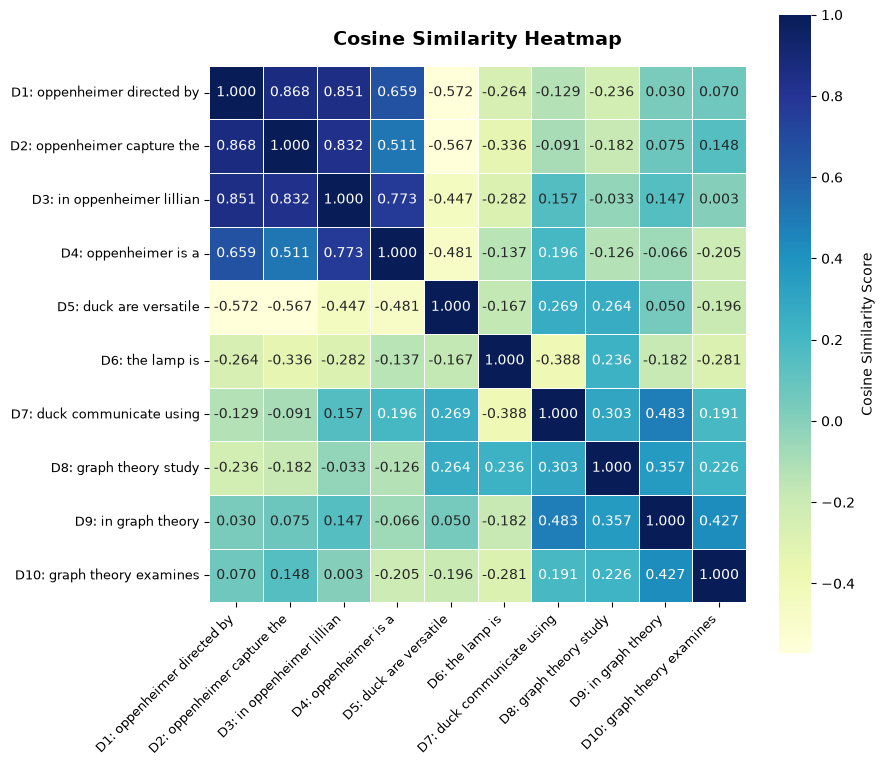

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns


def visualize_data(cosine_matrix, texts_processed):
  """Visualize the cosine similarity matrix from the previous task using a heatmap.

  Args:
      cosine_matrix (list): matrix of cosine similarity scores.
      texts_processed (list): list of texts, processed in previous task.

  Returns:
      None
  """
  if not cosine_matrix or not texts_processed:
    print("Помилка: дані для візуалізації відсутні.")
    return None

  labels = []
  for i, text in enumerate(texts_processed):
    words = text.split()
    snippet = " ".join(words[:3]) if words else "empty"
    labels.append(f"D{i+1}: {snippet}")

  n = len(texts_processed)
  plt.figure(figsize=(max(8, n * 0.9), max(6, n * 0.8)))

  ax = sns.heatmap(
      cosine_matrix,
      annot=True, 
      fmt=".3f", 
      cmap="YlGnBu", 
      xticklabels=labels,
      yticklabels=labels,
      square=True,  
      linewidths=0.5, 
      cbar_kws={"label": "Cosine Similarity Score"},
  )

  plt.title("Cosine Similarity Heatmap", fontsize=14, fontweight="bold", pad=15)
  plt.xticks(rotation=45, ha="right", fontsize=9)
  plt.yticks(rotation=0, fontsize=9)
  plt.tight_layout()

  plt.show()

visualize_data(cosine_matrix, texts_processed)

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

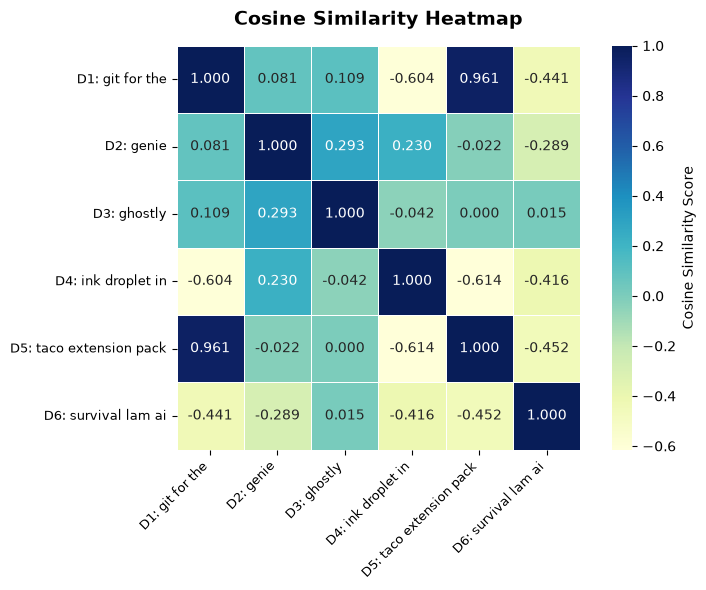

In [15]:
import json
import urllib.request


def get_texts():
  """Get the texts you want to analyse. Either API fetching, Kaggle or any other source.

  Args:
      None: None.

  Returns:
      list: list of texts.
  """
  top_stories_url = "https://hacker-news.firebaseio.com/v0/topstories.json"
  texts = []
  headers = {"User-Agent": "DataScienceProject/1.0"}

  try:
    req = urllib.request.Request(top_stories_url, headers=headers)
    with urllib.request.urlopen(req, timeout=5) as resp:
      story_ids = json.loads(resp.read().decode())[:6]  

      for sid in story_ids:
        item_url = f"https://hacker-news.firebaseio.com/v0/item/{sid}.json"
        req_item = urllib.request.Request(item_url, headers=headers)
        with urllib.request.urlopen(req_item, timeout=5) as item_resp:
          item_data = json.loads(item_resp.read().decode())
          if "title" in item_data:
            texts.append(item_data["title"])
  except Exception:
    pass

  if len(texts) < 6:
    texts = [
        "Artificial intelligence tools improve coding speed and quality.",
        "Machine learning models show breakthrough in weather prediction.",
        "New open-source database engine achieves record benchmark results.",
        "Data science techniques enable real-time detection of anomalies.",
        "Web assembly brings high performance applications to browsers.",
        "Python remains the most popular language for data analysis.",
    ]

  return texts

texts = get_texts()
texts_processed = process_texts(texts)
cosine_matrix = calcuate_tfidf(texts_processed)
visualize_data(cosine_matrix, texts_processed)